<a href="https://colab.research.google.com/github/prangunj23/CS163-Radio-Interferometry-Project/blob/main/GnnCAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U "sympy>=1.13.3"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import torch.nn as nn
!pip install -q pyuvdata tqdm
from tqdm.auto import tqdm
import numpy as np

In [ ]:
import sys
import os
sys.path.insert(0, "/content/drive/MyDrive/CS 163/cs163_lib")
os.environ["CS163_USER"] = "pranit"
from cs163 import results

# Data Loading and Helpers

In [ ]:
!cp -r "/content/drive/MyDrive/CS 163/cs163_tensors" /content/

X = np.load("/content/cs163_tensors/X.npy")   # uncalibrated visibilities: (10000 observations, real/imag, 214 antennas, 214 antennas)
G = np.load("/content/cs163_tensors/Y.npy")   # antenna gains: (10000 observations, real/imag, 214 antennas)
M = np.load("/content/cs163_tensors/M.npy")   # which antennas are good (True) or flagged (False): (10000, 214)

print("Uncalibrated visibilities:", X.shape)
print("Gains:", G.shape)

Uncalibrated visibilities: (10000, 2, 214, 214)
Gains: (10000, 2, 214)


In [ ]:
N_ANT = X.shape[2]
N_OBS = X.shape[0]
N_LAYERS = 16 # number of rounds of message passing
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH = 8
STEPS = 500


In [ ]:
def to_c(a): return a[:, 0].astype(np.float32) + 1j * a[:, 1].astype(np.float32)
off = ~np.eye(N_ANT, dtype=bool)
Gs = to_c(G[:400]); Gs = np.where(np.abs(Gs) > 0, Gs, 1)
S = to_c(X[:400]) / ((1/Gs)[:, :, None] * (1/Gs).conj()[:, None, :])
sky0 = np.median(S.real, 0) + 1j * np.median(S.imag, 0)      # median ignores the bad ~12%

DIRECT = np.zeros(N_OBS, bool)
for s in range(0, N_OBS, 200):
    Xc, Gc = to_c(X[s:s+200]), to_c(G[s:s+200]); Gc = np.where(np.abs(Gc) > 0, Gc, 1)
    def dev(g):
        Sb = Xc / (g[:, :, None] * g.conj()[:, None, :])
        return np.nanmedian((np.abs(Sb - sky0) / np.abs(sky0))[:, off], 1)
    DIRECT[s:s+200] = dev(Gc) < dev(1 / Gc)
print(DIRECT.sum(), "of", N_OBS, "observations store the applied gain directly")

2 of 10000 observations store the applied gain directly


In [ ]:
permutated = np.random.permutation(N_OBS)
train_frac = 0.8
n_train = int(train_frac * N_OBS)
train_idx, test_idx = permutated[:n_train], permutated[n_train:]
NOT_AUTO_COR = ~torch.eye(N_ANT, dtype=torch.bool)

In [ ]:
def load(idx):
  Xb = torch.tensor(X[idx], dtype=torch.float32)
  Gb = torch.tensor(G[idx], dtype=torch.float32)
  Mb = torch.tensor(M[idx], dtype=torch.bool)

  Xb = torch.nan_to_num(torch.complex(Xb[:, 0], Xb[:, 1]))
  Gb = torch.nan_to_num(torch.complex(Gb[:, 0], Gb[:, 1]))

  Gb = torch.where(torch.tensor(DIRECT[idx])[:, None], Gb, 1 / Gb)
  return Xb, Gb, Mb


def complex_outer(g):
  return g[:, :, None] * g.conj()[:, None, :]

def pair_mask(M):
  return M[:, :, None] & M[:, None, :] & NOT_AUTO_COR.to(M.device)

def complex_nanmedian(S):
  return torch.complex(torch.nanmedian(S.real, 0).values, torch.nanmedian(S.imag, 0).values)

# Clean Sky

In [ ]:
# Everything here comes from X only
Xs = torch.nan_to_num(torch.complex(torch.tensor(X[train_idx[:400], 0], dtype=torch.float32), torch.tensor(X[train_idx[:400], 1], dtype=torch.float32)))
SCALE = Xs.abs()[Xs.abs() > 0].median()          # put visibilities on a ~1 scale
Xs = Xs / SCALE
SKY_INIT = torch.complex(Xs.real.median(0).values, Xs.imag.median(0).values)   # starting point; the model learns the real sky
SKY = torch.where(SKY_INIT.abs() > 0, SKY_INIT, torch.ones_like(SKY_INIT))
del Xs

# Batching and Model Helpers

## Estimate

In [ ]:
def get_batch(idx):
  Xb, Gb, Mb = load(idx)
  Xb = Xb.to(DEVICE) / SCALE          # model input
  g = Gb.to(DEVICE)                   # target only
  Mf = Mb.float().to(DEVICE)          # target/eval only
  return Xb, g, Mf

In [ ]:
def loss_fn(g_pred, g_true, Mf):
  W = Mf[:, :, None] * Mf[:, None, :] * NOT_AUTO_COR.to(Mf.device)
  return ((complex_outer(g_pred) - complex_outer(g_true)).abs() ** 2 * W).sum() / W.sum()

def gain_error(g_pred, g_true, Mf):
  c = (g_pred.conj() * g_true * Mf).sum(1, keepdim=True)
  g_pred = g_pred * c / c.abs().clamp_min(1e-12)
  err = ((g_pred - g_true).abs() ** 2 * Mf).sum(1) / ((g_true.abs() ** 2) * Mf).sum(1)
  return err.sqrt()

## Estimated

In [ ]:
R_dim = 2
R_est = 2
resid_dim = 1
neighbor_gain_dim = 2
trust_score_dim = 1
gain_dim = 2

In [ ]:
def data_weights(Xb):                                     # edge weights from X alone
  ok = torch.isfinite(Xb.real) & (Xb.abs() > 0) & NOT_AUTO_COR.to(Xb.device)
  return ok.float()

def rank1_init(R, W, n_power=3):
  H = 0.5 * (R + R.conj().transpose(1, 2)) * W
  with torch.no_grad():
    v = torch.linalg.eigh(H)[1][:, :, -1]                 # warm start
  for _ in range(n_power):                                # differentiable, so gradients reach the learned sky
    v = torch.einsum("bij,bj->bi", H, v)
    v = v / v.norm(dim=1, keepdim=True).clamp_min(1e-12)
  lam = torch.einsum("bi,bij,bj->b", v.conj(), H, v).real[:, None]
  n = W.sum(2).mean(1, keepdim=True).clamp_min(1)
  return v * torch.sqrt(lam.clamp_min(0) * W.shape[1] / n)


class BlindGainGNN(nn.Module):
  def __init__(self, sky_init, hidden=32, n_layers=N_LAYERS, use_rank1=True):
    super().__init__()
    self.hidden, self.n_layers, self.use_rank1 = hidden, n_layers, use_rank1 # hidden represents size of hidden vector that acts as a scratchpad to store important values for computation
    self.sky = nn.Parameter(torch.view_as_real(sky_init.to(torch.complex64)).clone())   # learned sky
    self.msg_net = nn.Sequential(nn.Linear(R_dim + R_est + resid_dim + neighbor_gain_dim + hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden + trust_score_dim)) # Message Net for sharing information between adjacent nodes
    self.upd_net = nn.Sequential(nn.Linear(gain_dim + hidden + hidden, hidden), nn.ReLU(), nn.Linear(hidden, gain_dim + hidden)) # Update Net for updating internal understanding of what the gains should be
    if use_rank1:
      # untrained model returns the rank-1 solution unchanged
      nn.init.zeros_(self.upd_net[-1].weight); nn.init.zeros_(self.upd_net[-1].bias)

  def sky_c(self):
    V = torch.view_as_complex(self.sky)
    return 0.5 * (V + V.conj().T)                         # keep it Hermitian

  def forward(self, Xb):                                  # <-- only input is X
    Xb = torch.nan_to_num(Xb)
    B, A = Xb.shape[:2]
    W = data_weights(Xb)
    V = self.sky_c()
    R = Xb * V.conj() / (V.abs() ** 2).clamp_min(1e-6) * W
    r = torch.view_as_real(R)

    if self.use_rank1:
      g = torch.view_as_real(rank1_init(R, W)).contiguous()
    else:
      g = torch.zeros(B, A, 2, device=Xb.device)
      g[..., 0] = 1                                       # every gain starts at 1 + 0i
    h = torch.zeros(B, A, self.hidden, device=Xb.device)

    for _ in range(self.n_layers):
      node = torch.cat([g, h], -1)
      neighbor = node[:, None].expand(B, A, A, -1)
      gc = torch.view_as_complex(g.contiguous())
      est = R * gc[:, None, :]
      resid = (R - complex_outer(gc)).abs()[..., None]    # how badly this baseline fits right now
      o = self.msg_net(torch.cat([r, torch.view_as_real(est), resid, neighbor], -1))
      msg, gate = o[..., :-1], torch.sigmoid(o[..., -1] + 3.0)   # learned flagging, starts ≈ 1 to force model to learn about potential edges that are distrustful
      w = W * gate
      m = (msg * w[..., None]).sum(2) / w.sum(2, keepdim=True).clamp_min(1e-3)
      out = self.upd_net(torch.cat([g, h, m], -1))
      g = g + out[..., :2]
      h = h + out[..., 2:]
    return torch.view_as_complex(g.contiguous())

In [ ]:
model = BlindGainGNN(SKY, use_rank1=True).to(DEVICE)
opt = torch.optim.Adam([
  {"params": [model.sky], "lr": 1e-2},                                    # sky learns faster
  {"params": [p for n, p in model.named_parameters() if n != "sky"], "lr": 1e-3},
])
losses = []
for step in tqdm(range(STEPS), desc="Steps"):
  Xb, g_true, Mf = get_batch(np.random.choice(train_idx, BATCH, replace=False))
  loss = loss_fn(model(Xb), g_true, Mf)
  opt.zero_grad(); loss.backward(); opt.step()
  losses.append(loss.item())
  if step % 50 == 0:
    tqdm.write(f"step {step:5d}  loss {loss.item():.5f}")

Steps:   0%|          | 0/500 [00:00<?, ?it/s]

step     0  loss 20.98521
step    50  loss 1.08202
step   100  loss 0.92303
step   150  loss 0.29586
step   200  loss 0.02236
step   250  loss 0.01816
step   300  loss 0.01288
step   350  loss 0.01285
step   400  loss 0.01130
step   450  loss 0.01152


In [ ]:
n_eval = min(400, len(test_idx))
errs = []
with torch.no_grad():
  for k in tqdm(range(0, n_eval, BATCH)):
    Xb, g_true, Mf = get_batch(test_idx[k:k + BATCH])
    errs += gain_error(model(Xb), g_true, Mf).tolist()

print(f"GNN gain error on {n_eval} test observations: {np.mean(errs):.3%}")

  0%|          | 0/50 [00:00<?, ?it/s]

GNN gain error on 400 test observations: 6.761%


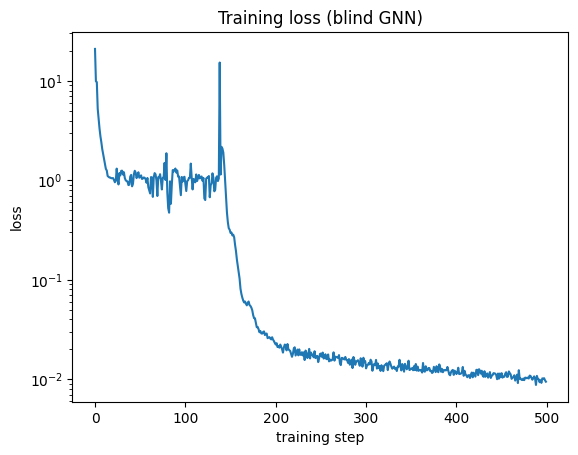

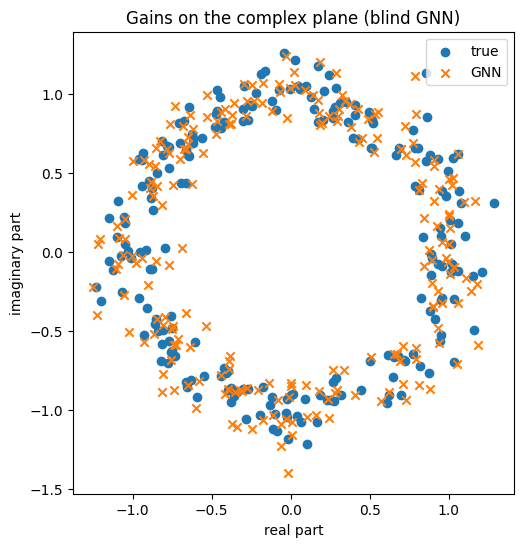

In [ ]:
import matplotlib.pyplot as plt

# 1. Loss plot
plt.plot(losses)
plt.yscale("log")
plt.xlabel("training step")
plt.ylabel("loss")
plt.title("Training loss (blind GNN)")
plt.savefig("loss_blind_gnn.jpg")
plt.show()

# 2. True vs GNN gains for one test observation, on the complex plane
Xb, g_true, Mf = get_batch(test_idx[:1])
with torch.no_grad():
  g_pred = model(Xb)

# line up the overall phase (it can't be measured), using good antennas only
c = (g_pred.conj() * g_true * Mf).sum()
g_pred = g_pred * c / c.abs()

good = Mf[0].bool().cpu()                    # only good antennas
gt = g_true[0].cpu()[good]
gp = g_pred[0].cpu()[good]

plt.figure(figsize=(6, 6))
plt.scatter(gt.real, gt.imag, label="true")
plt.scatter(gp.real, gp.imag, marker="x", label="GNN")
plt.xlabel("real part")
plt.ylabel("imaginary part")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Gains on the complex plane (blind GNN)")
plt.savefig("res_blind_gnn.jpg")
plt.show()

  0%|          | 0/50 [00:00<?, ?it/s]

Rank-1 only (learned sky) gain error on 400 test observations: 141.166%


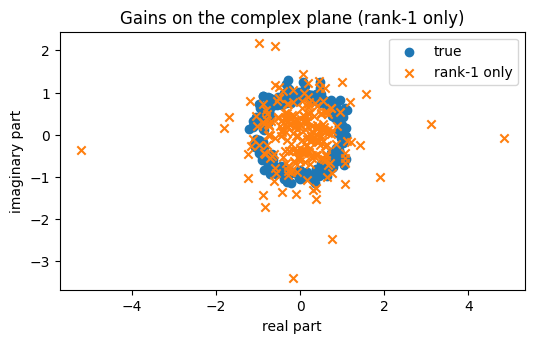

In [ ]:
# ---- Rank-1 (top eigenvector) solution only, no GNN ----
import matplotlib.pyplot as plt

def data_weights(Xb):                                     # good baselines, from X alone
  ok = torch.isfinite(Xb.real) & (Xb.abs() > 0) & NOT_AUTO_COR.to(Xb.device)
  return ok.float()

@torch.no_grad()
def rank1_only(Xb, V):
  Xb = torch.nan_to_num(Xb)
  W = data_weights(Xb)
  R = Xb * V.conj() / (V.abs() ** 2).clamp_min(1e-6) * W   # divide out the sky: ~ g_i conj(g_j)
  H = 0.5 * (R + R.conj().transpose(1, 2))                 # Hermitian part
  w, v = torch.linalg.eigh(H)                              # eigenvalues in ascending order
  n = W.sum(2).mean(1, keepdim=True).clamp_min(1)          # avg good baselines per antenna
  return v[:, :, -1] * torch.sqrt(w[:, -1:].clamp_min(0) * W.shape[1] / n)

# Sky to divide out: "learned" = sky from the trained BlindGainGNN, "init" = median-of-X starting sky
SKY_SOURCE = "learned"
with torch.no_grad():
  V_est = model.sky_c() if SKY_SOURCE == "learned" else SKY.to(DEVICE)

# Test-set error
n_eval = min(400, len(test_idx))
errs_r1 = []
for k in tqdm(range(0, n_eval, BATCH)):
  Xb, g_true, Mf = get_batch(test_idx[k:k + BATCH])
  errs_r1 += gain_error(rank1_only(Xb, V_est), g_true, Mf).tolist()
print(f"Rank-1 only ({SKY_SOURCE} sky) gain error on {n_eval} test observations: {np.mean(errs_r1):.3%}")

# 2. True vs rank-1 gains for one test observation, on the complex plane
Xb, g_true, Mf = get_batch(test_idx[:1])
with torch.no_grad():
  g_pred = rank1_only(Xb, V_est)

# line up the overall phase (it can't be measured), using good antennas only
c = (g_pred.conj() * g_true * Mf).sum()
g_pred = g_pred * c / c.abs()

good = Mf[0].bool().cpu()                    # only good antennas
gt = g_true[0].cpu()[good]
gp = g_pred[0].cpu()[good]

plt.figure(figsize=(6, 6))
plt.scatter(gt.real, gt.imag, label="true")
plt.scatter(gp.real, gp.imag, marker="x", label="rank-1 only")
plt.xlabel("real part")
plt.ylabel("imaginary part")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Gains on the complex plane (rank-1 only)")
plt.savefig("res_rank1_only.jpg")
plt.show()

In [ ]:
run_dir = results.save_model(
  "gain_gnn",
  model,
  results={
    "gnn_gain_error": np.mean(errs),
    "n_eval": n_eval,
  },
  params={
    "hidden": model.hidden, "n_layers": model.n_layers,
    "steps": STEPS, "batch": BATCH, "lr": 1e-3, "train_frac": train_frac,
  },
  notes="GNN with gain nodes (g_i + hidden h_i) and baseline edges r_ij = X_ij / V_ij. "
        "Loss compares g g^H. Gain error is measured after lining up the overall phase.",
  arrays={"test_idx": test_idx[:n_eval]},     # which observations were evaluated
)

saved -> /content/drive/MyDrive/CS 163/results/2026-11-02_034228_pranit_gain_gnn


In [ ]:
run_dir = results.save_model(
  "gain_eig_gnn",
  model,
  results={
    "gnn_gain_error": np.mean(errs),
    "n_eval": n_eval,
  },
  params={
    "hidden": model.hidden, "n_layers": model.n_layers,
    "steps": STEPS, "batch": BATCH, "lr": 1e-3, "train_frac": train_frac,
  },
  notes="GNN with gain nodes (g_i + hidden h_i) and baseline edges r_ij = X_ij / V_ij. The model learns corrections from eigensolution."
        "Loss compares g g^H. Gain error is measured after lining up the overall phase.",
  arrays={"test_idx": test_idx[:n_eval]},     # which observations were evaluated
)

saved -> /content/drive/MyDrive/CS 163/results/2026-11-02_035336_pranit_gain_eig_gnn
